<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 4 · Sesión 1: Árboles de decisión y CART (Breiman, Friedman, Olshen y Stone, 1984)</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: impureza, bondad de partición, CART desde cero, priors y costos, teorema de categóricas, poda por costo-complejidad, surrogates</div>
</div>

## Objetivos de la sesión (2 horas)

Derivar e implementar los elementos centrales de **CART** (*Classification and Regression Trees*, Breiman, Friedman, Olshen y Stone, 1984):

1. **Particiones binarias** y el conjunto de preguntas estándar (capítulo 2).
2. **Funciones de impureza** (Gini, entropía) y sus propiedades; por qué no se usa la tasa de error (capítulos 2 y 4).
3. La **bondad de una partición** $\Delta i(s,t)$ y su búsqueda exhaustiva; el **atajo para categóricas** (teorema 4.5).
4. **Priors y costos de mala clasificación** (capítulo 4), clave en riesgo de crédito.
5. **Poda por costo-complejidad** y el *weakest link* (capítulo 3); selección por validación cruzada con la regla de 1-SE.
6. **Surrogate splits** y la importancia de variables (capítulo 5).

Todo se implementa **desde cero** en NumPy y se verifica contra `scikit-learn`, que implementa CART.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 15 min | Árboles: particiones, nodos, hojas, preguntas |
| 2 | 25 min | Impureza y bondad de partición: derivación |
| 3 | 25 min | CART desde cero y verificación con scikit-learn |
| 4 | 15 min | Priors, costos y categóricas |
| 5 | 25 min | Poda por costo-complejidad y validación cruzada |
| 6 | 15 min | Surrogates, importancia, uso en crédito y ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

import warnings; warnings.filterwarnings("ignore")
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import roc_auc_score
app = pd.read_csv(DATA / "hc_application_sintetico.csv").drop_duplicates()
app["EDAD"] = -app.DAYS_BIRTH / 365.25
app["RCI"] = app.AMT_ANNUITY / (app.AMT_INCOME_TOTAL / 12)
app["EXT2"] = app.EXT_SOURCE_2.fillna(app.EXT_SOURCE_2.median()); app["EXT3"] = app.EXT_SOURCE_3.fillna(app.EXT_SOURCE_3.median())
app["PENSIONISTA"] = (app.DAYS_EMPLOYED == 365243).astype(int)
FEATS = ["EXT2", "EXT3", "EDAD", "RCI", "PENSIONISTA", "AMT_REQ_CREDIT_BUREAU_YEAR"]
dev = app[app.FECHA_SOLICITUD < "2025-01"]; oot = app[app.FECHA_SOLICITUD >= "2025-01"]
X, y = dev[FEATS].values, dev.TARGET.values
Xo, yo = oot[FEATS].values, oot.TARGET.values
print(X.shape, f"tasa de malos: {y.mean():.2%}")

(45092, 6) tasa de malos: 8.69%


## 1. El árbol como partición recursiva
CART divide el espacio de variables $\mathcal{X}$ con **preguntas binarias**. Cada nodo $t$ es un subconjunto de $\mathcal{X}$; los nodos terminales (hojas) $\tilde{T}$ forman una partición. El **conjunto de preguntas estándar** (Breiman et al., sección 2.4.1):
- para una variable ordenada $x_m$: ¿$x_m \le c$?, con $c$ en los puntos medios entre valores observados;
- para una categórica con valores $\{b_1,\dots,b_L\}$: ¿$x_m \in S$?, con $S$ un subconjunto propio.

Con $n$ valores distintos hay como máximo $n-1$ cortes por variable ordenada y $2^{L-1}-1$ por variable categórica.

## 2. Impureza y bondad de partición
Sea $p(j|t)$ la proporción de la clase $j$ en el nodo $t$. Una **función de impureza** $i(t) = \phi(p(1|t), \dots, p(J|t))$ debe ser (definición 2.5): máxima en $(1/J, \dots, 1/J)$, mínima (cero) en los nodos puros y simétrica.

| Impureza | Fórmula (J clases) | Dos clases, $p = p(1|t)$ |
|---|---|---|
| **Gini** | $1 - \sum_j p(j|t)^2 = \sum_{i \neq j} p(i|t)p(j|t)$ | $2p(1-p)$ |
| **Entropía** | $-\sum_j p(j|t) \log p(j|t)$ | $-p\log p - (1-p)\log(1-p)$ |
| Tasa de error | $1 - \max_j p(j|t)$ | $\min(p, 1-p)$ |

**Bondad de la partición** $s$ del nodo $t$ en $t_L$ y $t_R$, con $p_L$ y $p_R$ las fracciones de casos que van a cada lado:
$$\Delta i(s, t) = i(t) - p_L\, i(t_L) - p_R\, i(t_R)$$
CART elige $s^* = \arg\max_s \Delta i(s,t)$. Si $\phi$ es **estrictamente cóncava**, $\Delta i \ge 0$ con igualdad solo si $p(j|t_L) = p(j|t_R)$ (sección 4.1): toda partición útil reduce la impureza. La tasa de error no es estrictamente cóncava: muchas particiones útiles tienen $\Delta i = 0$, y por eso CART no la usa para crecer el árbol.

s1: (300,100) | (100,300)    ΔI Gini  = 0.1250
s1: (300,100) | (100,300)    ΔI Error = 0.2500
s2: (200,400) | (200,0)      ΔI Gini  = 0.1667
s2: (200,400) | (200,0)      ΔI Error = 0.2500


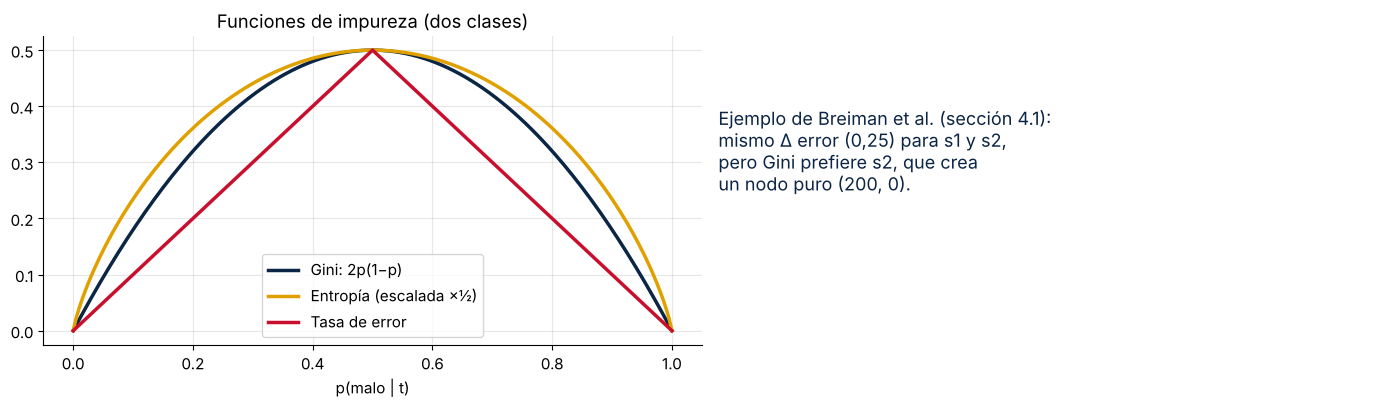

In [2]:
pgrid = np.linspace(0, 1, 201)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(pgrid, 2 * pgrid * (1 - pgrid), color=AZUL, lw=2.5, label="Gini: 2p(1−p)")
ent = -(pgrid * np.log2(np.clip(pgrid, 1e-12, 1)) + (1 - pgrid) * np.log2(np.clip(1 - pgrid, 1e-12, 1))) / 2
ax[0].plot(pgrid, ent, color=ORO, lw=2.5, label="Entropía (escalada ×½)")
ax[0].plot(pgrid, np.minimum(pgrid, 1 - pgrid), color=ROJO, lw=2.5, label="Tasa de error")
ax[0].legend(); ax[0].set_title("Funciones de impureza (dos clases)"); ax[0].set_xlabel("p(malo | t)")
# Ejemplo de la sección 4.1: dos particiones con el mismo error pero distinta "pureza"
padre = np.array([400, 400])
for nombre, (L, R) in {"s1: (300,100) | (100,300)": ([300, 100], [100, 300]), "s2: (200,400) | (200,0)": ([200, 400], [200, 0])}.items():
    L, R = np.array(L), np.array(R)
    def imp(c, f): p = c / c.sum(); return f(p)
    gini = lambda p: 1 - (p ** 2).sum(); err = lambda p: 1 - p.max()
    for nm, f in [("Gini", gini), ("Error", err)]:
        d = imp(padre, f) - L.sum() / 800 * imp(L, f) - R.sum() / 800 * imp(R, f)
        print(f"{nombre:28s} ΔI {nm:5s} = {d:.4f}")
ax[1].axis("off"); ax[1].text(0, .5, "Ejemplo de Breiman et al. (sección 4.1):\nmismo Δ error (0,25) para s1 y s2,\npero Gini prefiere s2, que crea\nun nodo puro (200, 0).", fontsize=13, color=AZUL)
plt.tight_layout(); plt.show()

## 3. CART desde cero
Búsqueda exhaustiva: para cada variable, ordenar los valores; recorrer los cortes candidatos actualizando incrementalmente los conteos a izquierda y derecha; calcular $\Delta i$ con Gini. La complejidad es $O(p \cdot n \log n)$ por nodo.

In [3]:
def gini_counts(n1, n):
    p = n1 / np.maximum(n, 1)
    return 2 * p * (1 - p)

def mejor_corte(X, y, min_hoja=1):
    n, n1 = len(y), y.sum()
    i_t = gini_counts(n1, n)
    mejor = (0.0, None, None)                        # (ΔI, variable, umbral)
    for j in range(X.shape[1]):
        o = np.argsort(X[:, j], kind="mergesort"); xs, ys = X[o, j], y[o]
        nL = np.arange(1, n); n1L = np.cumsum(ys)[:-1]                     # conteos a la izquierda para cada corte
        valido = (xs[1:] != xs[:-1]) & (nL >= min_hoja) & (n - nL >= min_hoja)
        if not valido.any(): continue
        dI = i_t - nL / n * gini_counts(n1L, nL) - (n - nL) / n * gini_counts(n1 - n1L, n - nL)
        dI = np.where(valido, dI, -1)
        k = int(np.argmax(dI))
        if dI[k] > mejor[0]: mejor = (dI[k], j, (xs[k] + xs[k + 1]) / 2)
    return mejor

def crecer(X, y, prof=0, max_prof=3, min_hoja=200):
    nodo = {"n": len(y), "p": y.mean()}
    if prof < max_prof and len(y) >= 2 * min_hoja:
        dI, j, c = mejor_corte(X, y, min_hoja)
        if j is not None and dI > 0:
            izq = X[:, j] <= c
            nodo.update(var=j, corte=c, dI=dI, L=crecer(X[izq], y[izq], prof + 1, max_prof, min_hoja), R=crecer(X[~izq], y[~izq], prof + 1, max_prof, min_hoja))
    return nodo

def predecir(nodo, x):
    while "var" in nodo:
        nodo = nodo["L"] if x[nodo["var"]] <= nodo["corte"] else nodo["R"]
    return nodo["p"]

def imprimir(nodo, prof=0):
    pad = "|   " * prof
    if "var" in nodo:
        print(f"{pad}{FEATS[nodo['var']]} <= {nodo['corte']:.4f}   (n={nodo['n']}, p={nodo['p']:.3f}, ΔI={nodo['dI']:.5f})")
        imprimir(nodo["L"], prof + 1); imprimir(nodo["R"], prof + 1)
    else:
        print(f"{pad}hoja: n={nodo['n']}, PD={nodo['p']:.3%}")

import time; t0 = time.time()
arbol = crecer(X, y, max_prof=3, min_hoja=200)
print(f"Árbol propio en {time.time() - t0:.1f} s\n"); imprimir(arbol)

Árbol propio en 0.1 s

EXT2 <= 0.3718   (n=45092, p=0.087, ΔI=0.00619)
|   EXT2 <= 0.2203   (n=5800, p=0.232, ΔI=0.01002)
|   |   EXT3 <= 0.1324   (n=1146, p=0.374, ΔI=0.01685)
|   |   |   hoja: n=234, PD=55.556%
|   |   |   hoja: n=912, PD=32.785%
|   |   EDAD <= 39.8522   (n=4654, p=0.197, ΔI=0.00489)
|   |   |   hoja: n=2123, PD=25.059%
|   |   |   hoja: n=2531, PD=15.132%
|   EXT2 <= 0.5915   (n=39292, p=0.065, ΔI=0.00183)
|   |   EXT3 <= 0.2878   (n=14735, p=0.105, ΔI=0.00168)
|   |   |   hoja: n=2643, PD=16.648%
|   |   |   hoja: n=12092, PD=9.097%
|   |   EXT3 <= 0.3760   (n=24557, p=0.042, ΔI=0.00048)
|   |   |   hoja: n=2347, PD=8.948%
|   |   |   hoja: n=22210, PD=3.706%


In [4]:
sk = DecisionTreeClassifier(criterion="gini", max_depth=3, min_samples_leaf=200, random_state=0).fit(X, y)
print(export_text(sk, feature_names=FEATS, decimals=4, show_weights=False))
p_own = np.array([predecir(arbol, x) for x in Xo]); p_sk = sk.predict_proba(Xo)[:, 1]
print(f"Máxima diferencia de PD entre nuestro CART y scikit-learn: {np.abs(p_own - p_sk).max():.2e}")
print(f"AUC fuera de tiempo: propio {roc_auc_score(yo, p_own):.4f} | scikit-learn {roc_auc_score(yo, p_sk):.4f}")

|--- EXT2 <= 0.3718
|   |--- EXT2 <= 0.2203
|   |   |--- EXT3 <= 0.1324
|   |   |   |--- class: 1
|   |   |--- EXT3 >  0.1324
|   |   |   |--- class: 0
|   |--- EXT2 >  0.2203
|   |   |--- EDAD <= 39.8522
|   |   |   |--- class: 0
|   |   |--- EDAD >  39.8522
|   |   |   |--- class: 0
|--- EXT2 >  0.3718
|   |--- EXT2 <= 0.5915
|   |   |--- EXT3 <= 0.2878
|   |   |   |--- class: 0
|   |   |--- EXT3 >  0.2878
|   |   |   |--- class: 0
|   |--- EXT2 >  0.5915
|   |   |--- EXT3 <= 0.3760
|   |   |   |--- class: 0
|   |   |--- EXT3 >  0.3760
|   |   |   |--- class: 0

Máxima diferencia de PD entre nuestro CART y scikit-learn: 0.00e+00
AUC fuera de tiempo: propio 0.7068 | scikit-learn 0.7068


**Verificación:** nuestro algoritmo encuentra las mismas particiones y produce las mismas PD que scikit-learn (que implementa CART con Gini). Un árbol de profundidad 3 ya funciona como una **segmentación de riesgo**: 8 segmentos con PD muy distintas, definidos por reglas legibles.

## 4. Priors, costos de mala clasificación y variables categóricas
### 4.1 Priors y costos (capítulo 4)
En crédito, un malo aprobado cuesta mucho más que un bueno rechazado. CART incorpora **costos** $C(i|j)$ (clasificar como $i$ un caso de clase $j$) y **priors** $\pi(j)$. Un resultado clave del libro (sección 4.4): con dos clases, los costos equivalen a **alterar los priors**:
$$\pi'(j) = \frac{C(j)\,\pi(j)}{\sum_k C(k)\,\pi(k)}, \qquad C(j) = \text{costo de equivocarse con la clase } j$$
En scikit-learn esto se implementa con `class_weight`, que repondera los casos al calcular la impureza.

In [5]:
# Costo de aprobar un malo = 60 % del monto; de rechazar un bueno = 8,25 % del monto (Módulo 1)
pesos = {0: 0.0825, 1: 0.60}
sk_c = DecisionTreeClassifier(max_depth=3, min_samples_leaf=200, class_weight=pesos, random_state=0).fit(X, y)
pi = np.array([1 - y.mean(), y.mean()]); Cj = np.array([pesos[0], pesos[1]])
print("Priors originales:", pi.round(4), "| priors alterados por los costos:", (Cj * pi / (Cj * pi).sum()).round(4))
for nombre, m in [("Sin costos", sk), ("Con costos (class_weight)", sk_c)]:
    hojas = m.apply(Xo); clasif = m.predict(Xo)
    print(f"{nombre:28s} hojas clasificadas 'malo': {len(np.unique(hojas[clasif == 1]))} de {m.get_n_leaves()} | rechazo {clasif.mean():.1%} | AUC {roc_auc_score(yo, m.predict_proba(Xo)[:, 1]):.4f}")

Priors originales: [0.9131 0.0869] | priors alterados por los costos: [0.5911 0.4089]
Sin costos                   hojas clasificadas 'malo': 1 de 8 | rechazo 0.4% | AUC 0.7068
Con costos (class_weight)    hojas clasificadas 'malo': 3 de 8 | rechazo 10.3% | AUC 0.7233


**Lectura:** sin costos, con 8 % de malos, solo la hoja más riesgosa (PD 56 %) tiene mayoría de malos: el árbol rechaza apenas el 0,4 % de los casos. Con los costos del negocio, las hojas de alto riesgo pasan a clasificarse como "rechazo". Los costos cambian la **regla de asignación** (y pueden cambiar las particiones), no solo el umbral.

### 4.2 El atajo para variables categóricas (teorema 4.5)
Con $L$ categorías hay $2^{L-1}-1$ particiones posibles. Breiman et al. demuestran que, con dos clases, basta **ordenar las categorías por $p(1|x = b_\ell)$** y evaluar solo los $L-1$ cortes en ese orden: la partición óptima está entre ellos. Verifiquémoslo con `OCCUPATION_TYPE`.

In [6]:
from itertools import combinations
occ = dev.OCCUPATION_TYPE.fillna("Sin dato").values
cats = pd.Series(y).groupby(occ).mean().sort_values()
def dI_subset(S):
    izq = np.isin(occ, list(S)); n, nL = len(y), izq.sum()
    return gini_counts(y.sum(), n) - nL / n * gini_counts(y[izq].sum(), nL) - (n - nL) / n * gini_counts(y[~izq].sum(), n - nL)
t0 = time.time(); todas = list(cats.index[1:])      # fijar una categoría reduce a 2^(L-1) subconjuntos
mejor_bruto = max((dI_subset((cats.index[0],) + S), (cats.index[0],) + S) for r in range(0, len(todas)) for S in combinations(todas, r))
t_bruto = time.time() - t0
t0 = time.time(); mejor_orden = max((dI_subset(tuple(cats.index[:k])), tuple(cats.index[:k])) for k in range(1, len(cats)))
print(f"{len(cats)} categorías: {2 ** (len(cats) - 1) - 1:,} particiones por fuerza bruta ({t_bruto:.1f} s) vs. {len(cats) - 1} por el orden ({time.time() - t0:.3f} s)")
print(f"ΔI fuerza bruta = {mejor_bruto[0]:.6f} | ΔI por el orden = {mejor_orden[0]:.6f}")
print("Mismo subconjunto:", set(mejor_bruto[1]) == set(mejor_orden[1]) or set(mejor_bruto[1]) == set(cats.index) - set(mejor_orden[1]))

13 categorías: 4,095 particiones por fuerza bruta (18.6 s) vs. 12 por el orden (0.062 s)
ΔI fuerza bruta = 0.001003 | ΔI por el orden = 0.001003
Mismo subconjunto: True


## 5. Poda por costo-complejidad (capítulo 3)
Detener el crecimiento con reglas de parada funciona mal (una partición poco útil puede habilitar otras muy útiles debajo). CART crece un árbol grande $T_{max}$ y luego lo **poda**. Para $\alpha \ge 0$:
$$R_\alpha(T) = R(T) + \alpha\,|\tilde{T}|$$
donde $R(T)$ es el costo (en CART, el error de resustitución; en scikit-learn, la impureza ponderada) y $|\tilde{T}|$ el número de hojas. **Weakest link:** para cada nodo interno $t$, con $T_t$ la rama que cuelga de él,
$$g(t) = \frac{R(t) - R(T_t)}{|\tilde{T}_t| - 1}$$
es el $\alpha$ a partir del cual conviene colapsar la rama. Podar sucesivamente el nodo de menor $g(t)$ produce una **secuencia anidada** de subárboles $T_1 \supset T_2 \supset \dots \supset \{t_1\}$ con umbrales $\alpha_1 < \alpha_2 < \dots$ (teorema 3.10). El $\alpha$ final se elige por **validación cruzada** con la **regla de 1-SE**: el árbol más simple cuyo error está a menos de un error estándar del mínimo.

Árbol grande: 597 hojas. Primer weakest link a mano: g = 1.162e-07 | scikit-learn α₁ = 1.162e-07


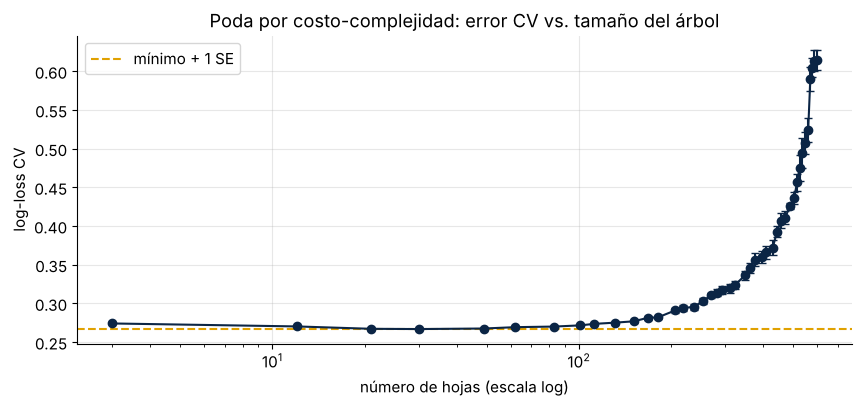

α mínimo CV → 30 hojas | regla 1-SE → α = 1.20e-04, 21 hojas | AUC oot = 0.7318


In [7]:
grande = DecisionTreeClassifier(min_samples_leaf=50, random_state=0).fit(X, y)
path = grande.cost_complexity_pruning_path(X, y)
alphas, imps = path.ccp_alphas, path.impurities
# Weakest link a mano sobre la estructura del árbol grande (impureza ponderada, como scikit-learn)
tr = grande.tree_; n = tr.weighted_n_node_samples; N = n[0]
R_nodo = tr.impurity * n / N
def hojas_y_R(t):
    if tr.children_left[t] == -1: return 1, R_nodo[t]
    a, b = hojas_y_R(tr.children_left[t]), hojas_y_R(tr.children_right[t]); return a[0] + b[0], a[1] + b[1]
internos = [t for t in range(tr.node_count) if tr.children_left[t] != -1]
g = []
for t in internos:
    nh, RT = hojas_y_R(t); g.append((R_nodo[t] - RT) / (nh - 1))
print(f"Árbol grande: {grande.get_n_leaves()} hojas. Primer weakest link a mano: g = {min(g):.3e} | scikit-learn α₁ = {alphas[1]:.3e}")

cv = StratifiedKFold(5, shuffle=True, random_state=0)
sub_alphas = alphas[::max(1, len(alphas) // 40)]
res = []
for a in sub_alphas:
    s = cross_val_score(DecisionTreeClassifier(min_samples_leaf=50, ccp_alpha=a, random_state=0), X, y, cv=cv, scoring="neg_log_loss")
    res.append((a, -s.mean(), s.std() / np.sqrt(len(s)), DecisionTreeClassifier(min_samples_leaf=50, ccp_alpha=a, random_state=0).fit(X, y).get_n_leaves()))
r = pd.DataFrame(res, columns=["alpha", "logloss_cv", "se", "hojas"])
i_min = r.logloss_cv.idxmin(); umbral = r.logloss_cv[i_min] + r.se[i_min]
a_1se = r[r.logloss_cv <= umbral].alpha.max()
fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(r.hojas, r.logloss_cv, yerr=r.se, fmt="o-", color=AZUL, capsize=3); ax.set_xscale("log")
ax.axhline(umbral, color=ORO, ls="--", label="mínimo + 1 SE")
ax.set_xlabel("número de hojas (escala log)"); ax.set_ylabel("log-loss CV"); ax.legend(); ax.set_title("Poda por costo-complejidad: error CV vs. tamaño del árbol"); plt.show()
podado = DecisionTreeClassifier(min_samples_leaf=50, ccp_alpha=a_1se, random_state=0).fit(X, y)
print(f"α mínimo CV → {r.hojas[i_min]} hojas | regla 1-SE → α = {a_1se:.2e}, {podado.get_n_leaves()} hojas | AUC oot = {roc_auc_score(yo, podado.predict_proba(Xo)[:, 1]):.4f}")

## 6. Surrogate splits, importancia y uso en crédito
**Surrogate splits (sección 5.3):** para cada partición $s^*$, CART busca en otras variables la partición $\tilde{s}$ que mejor **imita** a $s^*$ (máxima probabilidad de mandar los casos al mismo lado). Si falta la variable principal, el caso sigue al mejor surrogate disponible. scikit-learn no implementa surrogates (rpart en R sí); lo calculamos a mano para la raíz.

In [8]:
j0, c0 = tr.feature[0], tr.threshold[0]
izq0 = X[:, j0] <= c0
sur = []
for j in range(X.shape[1]):
    if j == j0: continue
    vals = np.unique(np.quantile(X[:, j], np.linspace(0.01, 0.99, 99)))
    mejor = max(((max(((X[:, j] <= c) == izq0).mean(), ((X[:, j] > c) == izq0).mean()), c) for c in vals))
    sur.append((FEATS[j], mejor[1], mejor[0]))
regla_mayoria = max(izq0.mean(), 1 - izq0.mean())
print(f"Partición principal: {FEATS[j0]} <= {c0:.4f}. Regla de mayoría: {regla_mayoria:.1%} de acuerdo")
pd.DataFrame(sur, columns=["surrogate", "corte", "% de acuerdo"]).sort_values("% de acuerdo", ascending=False).style.format({"corte": "{:.4f}", "% de acuerdo": "{:.1%}"})

Partición principal: EXT2 <= 0.3718. Regla de mayoría: 87.1% de acuerdo


,surrogate,corte,% de acuerdo
0,EXT3,0.1824,88.0%
3,PENSIONISTA,1.0000,87.1%
4,AMT_REQ_CREDIT_BUREAU_YEAR,6.0000,86.9%
2,RCI,1.7694,86.6%
1,EDAD,21.5330,86.5%


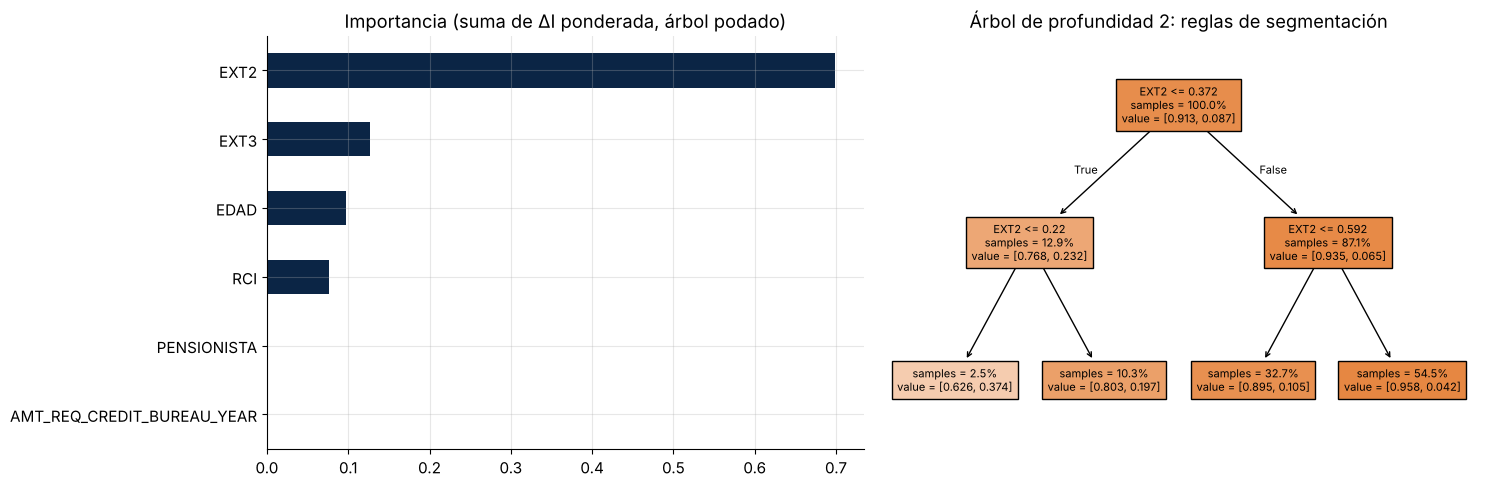

In [9]:
imp = pd.Series(podado.feature_importances_, index=FEATS).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
imp.plot(kind="barh", ax=ax[0], color=AZUL); ax[0].set_title("Importancia (suma de ΔI ponderada, árbol podado)")
plot_tree(DecisionTreeClassifier(max_depth=2, min_samples_leaf=500).fit(X, y), feature_names=FEATS, filled=True, proportion=True, ax=ax[1], fontsize=8, impurity=False)
ax[1].set_title("Árbol de profundidad 2: reglas de segmentación"); plt.tight_layout(); plt.show()

**Lectura:** el mejor surrogate (`EXT3`) apenas supera a la regla de mayoría (88,0 % vs. 87,1 %): ninguna otra variable imita bien al score externo. Cuando falta `EXT2`, CART enviaría esos casos casi como "al lado mayoritario". Es un buen diagnóstico de cuán **insustituible** es una variable.

**Árboles en riesgo de crédito:**
- **Ventajas:** reglas legibles (segmentación, políticas), capturan **interacciones** y no linealidades sin especificarlas, tratan faltantes de forma natural.
- **Desventajas:** **alta varianza** (pequeños cambios en los datos cambian la estructura), predicciones escalonadas (pocas PD distintas), menor discriminación que una logística bien construida.
- **Usos típicos:** segmentar antes de construir scorecards, detectar interacciones para la logística, reglas de política y, sobre todo, como **base de los ensembles** (sesiones 2-4).

## Ejercicios
1. Cambia el criterio a `entropy`. ¿Cambian las particiones del árbol de profundidad 3?
2. Agrega a `crecer` un parámetro de priors alterados (repondera los conteos) y verifica que coincide con `class_weight`.
3. Entrena el árbol podado en 5 submuestras distintas. ¿Cuántas veces cambia la variable de la raíz? (Motivación de la sesión 2.)
4. Implementa la predicción con el surrogate cuando `EXT2` está ausente.